# 04 — Modelagem

## Modelagem, otimização de hiperparâmetros e interpretação

### Planejamento

1. **Preparar os dados:** carregar as bases de treino, teste OOT e submissão, respeitando as partições já definidas. Não imputar valores ausentes.
2. **Treinar o XGBoost baseline:** usar seed fixa e parâmetros iniciais; registrar AUC no treino e no teste OOT.
3. **Treinar o LightGBM baseline:** usar a mesma seed e avaliar com as mesmas métricas.
4. **Comparar os baselines:** analisar desempenho e diferença entre AUC de treino e OOT, considerando que o OOT já foi consultado nas análises anteriores.
5. **Otimizar o melhor modelo com Optuna:** usar validação temporal interna walk-forward para orientar a busca de hiperparâmetros, sem selecionar parâmetros pela avaliação OOT.
6. **Avaliar o modelo otimizado:** medir o desempenho final no teste OOT e comparar com o baseline correspondente.
7. **Avaliar o modelo otimizado no conjunto de contratos rejeitados:** comparar o score com treino/submissao. Esperado que a média de scores seja maior.
7. **Interpretar o modelo com SHAP:** examinar a importância global das variáveis e a direção de seus efeitos, com foco no modelo selecionado.

### Princípios

- Manter a separação temporal existente entre treino e teste OOT.
- Preservar valores ausentes; não aplicar imputação.
- Usar categóricas nativas dos modelos quando suportadas.
- Fixar e registrar as seeds para reprodutibilidade.
- Documentar parâmetros, métricas e decisões de modelagem.

### Para lembrar:

- Avaliar usar QuantileTransformer do sklearn
- **Avaliar o modelo otimizado no conjunto de contratos rejeitados:** pode aplicar o modelo em abt_completa filtrada para o conjunto de rejeitados.
- Mostrar a evolução do AUC por safra! Pode mostrar no treino mesmo, dentro do cross validation.
- No mercado, usa-se o quantiletransforme por safra, assim vc ve o perfil da probabilidade agrupado para ver se é estável ao longo do tempo!

In [41]:
import importlib
import sys
from pathlib import Path
sys.path.append("..")

import src.functions as fn #Funcoes criadas no projeto
importlib.reload(fn)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import QuantileTransformer

# ============================================================
# 1. Configurações e carregamento das bases
# ============================================================

CAMINHO_PROCESSADOS = Path("../dados/processados")

CAMINHO_TREINO_TESTE = (
    CAMINHO_PROCESSADOS / "abt_modelagem_treino_teste.parquet"
)
CAMINHO_SUBMISSAO = (
    CAMINHO_PROCESSADOS / "abt_modelagem_submissao.parquet"
)

COL_TARGET = "OVER60MOB12"
COL_PARTICAO = "particao"
COL_ID_CONTRATO = "id_contrato"
COL_ID_CLIENTE = "id_cliente"

SEED = 42

FEATURES_MODELO = [
    "tipo_contrato",
    "qtd_filhos",
    "qtd_membros_familia",
    "renda_anual",
    "tipo_renda",
    "ocupacao",
    "tipo_organizacao",
    "nivel_educacao",
    "estado_civil",
    "tipo_moradia",
    "possui_carro",
    "possui_imovel",
    "nota_regiao_cliente",
    "nota_regiao_cliente_cidade",
    "parc_atrasadas_por_contrato_exec",
    "pct_parc_atrasadas_360d",
    "atraso_medio_720d",
    "qtd_contratos_executados",
    "pct_parc_atrasadas_180d",
    "pct_parc_pagas_a_menos_720d",
    "parc_gt90_por_contrato_exec",
    "razao_credito_atual_media_720d",
    "parc_gt30_por_mes_rel",
    "qtd_parc_vencidas_360d",
    "pct_parc_atraso_gt30_180d",
    "qtd_aprovados_360d",
    "idade_anos",
]

# Variáveis mantidas para análise e construção de políticas.
# Não serão utilizadas como preditoras nos modelos.
VARIAVEIS_POLITICA = [
    "valor_credito",
    "valor_bem",
    "valor_parcela",
    "razao_credito_renda",
    "razao_parcela_renda",
    "razao_credito_bem",
]

FEATURES_CATEGORICAS = [
    "tipo_contrato",
    "tipo_renda",
    "ocupacao",
    "tipo_organizacao",
    "nivel_educacao",
    "estado_civil",
    "tipo_moradia",
    "possui_carro",
    "possui_imovel",
]

assert len(FEATURES_MODELO) == 27
assert len(set(FEATURES_MODELO)) == len(FEATURES_MODELO)
assert len(VARIAVEIS_POLITICA) == 6
assert len(set(VARIAVEIS_POLITICA)) == len(VARIAVEIS_POLITICA)
assert not set(FEATURES_MODELO).intersection(VARIAVEIS_POLITICA)
assert set(FEATURES_CATEGORICAS).issubset(FEATURES_MODELO)

abt_modelagem_treino_teste = pd.read_parquet(CAMINHO_TREINO_TESTE)
abt_modelagem_submissao = pd.read_parquet(CAMINHO_SUBMISSAO)


# ============================================================
# 2. Validações estruturais
# ============================================================

COLUNAS_OBRIGATORIAS_TREINO = [
    COL_ID_CONTRATO,
    COL_ID_CLIENTE,
    COL_TARGET,
    COL_PARTICAO,
    *FEATURES_MODELO,
    *VARIAVEIS_POLITICA,
]

COLUNAS_OBRIGATORIAS_SUBMISSAO = [
    COL_ID_CLIENTE,
    *FEATURES_MODELO,
    *VARIAVEIS_POLITICA,
]

COLUNAS_AUSENTES_TREINO = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_TREINO
    if coluna not in abt_modelagem_treino_teste.columns
]

COLUNAS_AUSENTES_SUBMISSAO = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS_SUBMISSAO
    if coluna not in abt_modelagem_submissao.columns
]

if COLUNAS_AUSENTES_TREINO:
    raise KeyError(
        "Colunas ausentes na base treino/teste: "
        f"{COLUNAS_AUSENTES_TREINO}"
    )

if COLUNAS_AUSENTES_SUBMISSAO:
    raise KeyError(
        "Colunas ausentes na base de submissão: "
        f"{COLUNAS_AUSENTES_SUBMISSAO}"
    )

if COL_TARGET in abt_modelagem_submissao.columns:
    raise ValueError("A base de submissão não deve conter o target.")

if abt_modelagem_treino_teste[COL_TARGET].isna().any():
    raise ValueError("Há valores nulos no target da base treino/teste.")

if abt_modelagem_treino_teste[COL_ID_CONTRATO].isna().any():
    raise ValueError("Há id_contrato nulo na base treino/teste.")

if abt_modelagem_treino_teste[COL_ID_CONTRATO].duplicated().any():
    raise ValueError("Há contratos duplicados na base treino/teste.")

if abt_modelagem_treino_teste[COL_PARTICAO].isna().any():
    raise ValueError("Há valores nulos na coluna de partição.")

particoes_esperadas = {"treino", "teste_oot"}
particoes_encontradas = set(
    abt_modelagem_treino_teste[COL_PARTICAO].unique()
)

if particoes_encontradas != particoes_esperadas:
    raise ValueError(
        "Partições inesperadas. "
        f"Esperadas: {particoes_esperadas}; "
        f"encontradas: {particoes_encontradas}."
    )

valores_target = set(
    abt_modelagem_treino_teste[COL_TARGET].unique()
)
if not valores_target.issubset({0, 1}):
    raise ValueError(
        "O target deve conter somente os valores 0 e 1; "
        f"valores encontrados: {valores_target}."
    )


# ============================================================
# 3. Separação das partições oficiais
# ============================================================

base_treino = abt_modelagem_treino_teste.loc[
    abt_modelagem_treino_teste[COL_PARTICAO].eq("treino")
].copy()

base_teste_oot = abt_modelagem_treino_teste.loc[
    abt_modelagem_treino_teste[COL_PARTICAO].eq("teste_oot")
].copy()

if len(base_treino) != 83_335:
    raise ValueError(
        "Esperadas 83.335 linhas de treino; "
        f"encontradas {len(base_treino):,}."
    )

if len(base_teste_oot) != 20_822:
    raise ValueError(
        "Esperadas 20.822 linhas de teste OOT; "
        f"encontradas {len(base_teste_oot):,}."
    )

ids_treino = pd.Index(base_treino[COL_ID_CONTRATO])
ids_teste_oot = pd.Index(base_teste_oot[COL_ID_CONTRATO])

ids_comuns = ids_treino.intersection(ids_teste_oot)
if len(ids_comuns) > 0:
    raise ValueError(
        f"Treino e teste OOT compartilham {len(ids_comuns):,} contratos."
    )

# As matrizes X contêm somente as 27 features do modelo.
X_treino = base_treino.loc[:, FEATURES_MODELO].copy()
y_treino = base_treino[COL_TARGET].astype("int8")

X_teste_oot = base_teste_oot.loc[:, FEATURES_MODELO].copy()
y_teste_oot = base_teste_oot[COL_TARGET].astype("int8")

X_submissao = abt_modelagem_submissao.loc[:, FEATURES_MODELO].copy()

# Mantém as variáveis destinadas às políticas fora das matrizes X.
politicas_treino = base_treino.loc[:, VARIAVEIS_POLITICA].copy()
politicas_teste_oot = base_teste_oot.loc[:, VARIAVEIS_POLITICA].copy()
politicas_submissao = abt_modelagem_submissao.loc[
    :, VARIAVEIS_POLITICA
].copy()


# ============================================================
# 4. Tratamento consistente das variáveis categóricas
# ============================================================

# O domínio categórico é aprendido exclusivamente no treino.
# Categorias inéditas no OOT ou na submissão tornam-se ausentes,
# sem incorporar informação dessas bases à preparação do modelo.
for coluna in FEATURES_CATEGORICAS:
    categorias_treino = (
        X_treino[coluna]
        .astype("string")
        .dropna()
        .unique()
        .tolist()
    )

    dtype_categoria = pd.CategoricalDtype(
        categories=sorted(categorias_treino),
        ordered=False,
    )

    X_treino[coluna] = (
        X_treino[coluna].astype("string").astype(dtype_categoria)
    )
    X_teste_oot[coluna] = (
        X_teste_oot[coluna].astype("string").astype(dtype_categoria)
    )
    X_submissao[coluna] = (
        X_submissao[coluna].astype("string").astype(dtype_categoria)
    )


# ============================================================
# 5. Verificações finais e resumo
# ============================================================

for nome, X in [
    ("treino", X_treino),
    ("teste OOT", X_teste_oot),
    ("submissão", X_submissao),
]:
    variaveis_de_politica_em_X = [
        coluna
        for coluna in VARIAVEIS_POLITICA
        if coluna in X.columns
    ]
    if variaveis_de_politica_em_X:
        raise ValueError(
            f"Variáveis de política encontradas em X de {nome}: "
            f"{variaveis_de_politica_em_X}"
        )

assert X_treino.columns.tolist() == FEATURES_MODELO
assert X_teste_oot.columns.tolist() == FEATURES_MODELO
assert X_submissao.columns.tolist() == FEATURES_MODELO

print(f"Features do modelo: {len(FEATURES_MODELO)}")
print(f"Variáveis de política: {len(VARIAVEIS_POLITICA)}")
print(
    f"Treino: {X_treino.shape} | "
    f"taxa de maus: {y_treino.mean():.4%}"
)
print(
    f"Teste OOT: {X_teste_oot.shape} | "
    f"taxa de maus: {y_teste_oot.mean():.4%}"
)
print(f"Submissão: {X_submissao.shape}")
print(
    "Valores ausentes nas features de treino:",
    f"{X_treino.isna().sum().sum():,}",
)
print("\nTipos das features de treino:")
print(X_treino.dtypes.value_counts())
print("\nVariáveis reservadas para políticas:")
print(VARIAVEIS_POLITICA)

/tmp/ipykernel_70213/1362814038.py:261: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_submissao[coluna].astype("string").astype(dtype_categoria)


Features do modelo: 27
Variáveis de política: 6
Treino: (83335, 27) | taxa de maus: 6.9695%
Teste OOT: (20822, 27) | taxa de maus: 7.8667%
Submissão: (50400, 27)
Valores ausentes nas features de treino: 442,730

Tipos das features de treino:
float32     12
Int64        2
float64      2
category     2
int64        2
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

Variáveis reservadas para políticas:
['valor_credito', 'valor_bem', 'valor_parcela', 'razao_credito_renda', 'razao_parcela_renda', 'razao_credito_bem']


In [42]:
# ============================================================
# Diagnóstico de ausências e categorias fora do treino
# Não altera as bases.
# ============================================================

features_categoricas = X_treino.select_dtypes(
    include=["category", "object", "string"]
).columns.tolist()

features_numericas = [
    coluna
    for coluna in FEATURES_MODELO
    if coluna not in features_categoricas
]

print(f"Features categóricas ({len(features_categoricas)}):")
print(features_categoricas)

print(f"\nFeatures numéricas ({len(features_numericas)}):")
print(features_numericas)

# Ausências por feature e partição.
resumo_ausencias = pd.DataFrame({
    "treino": X_treino.isna().mean(),
    "teste_oot": X_teste_oot.isna().mean(),
    "submissao": X_submissao.isna().mean(),
}).sort_values("treino", ascending=False)

print("\nPercentual de valores ausentes:")
display(resumo_ausencias)

# Categorias observadas na submissão que não existem no treino.
for coluna in features_categoricas:
    categorias_treino = set(X_treino[coluna].dropna().astype("string").unique())
    categorias_submissao = set(X_submissao[coluna].dropna().astype("string").unique())
    categorias_novas = sorted(categorias_submissao - categorias_treino)

    print(
        f"{coluna}: {len(categorias_treino)} categorias no treino, "
        f"{len(categorias_novas)} categorias novas na submissão"
    )

    if categorias_novas:
        print(f"  Novas categorias: {categorias_novas[:20]}")

Features categóricas (9):
['tipo_contrato', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel']

Features numéricas (18):
['qtd_filhos', 'qtd_membros_familia', 'renda_anual', 'nota_regiao_cliente', 'nota_regiao_cliente_cidade', 'parc_atrasadas_por_contrato_exec', 'pct_parc_atrasadas_360d', 'atraso_medio_720d', 'qtd_contratos_executados', 'pct_parc_atrasadas_180d', 'pct_parc_pagas_a_menos_720d', 'parc_gt90_por_contrato_exec', 'razao_credito_atual_media_720d', 'parc_gt30_por_mes_rel', 'qtd_parc_vencidas_360d', 'pct_parc_atraso_gt30_180d', 'qtd_aprovados_360d', 'idade_anos']

Percentual de valores ausentes:


,treino,teste_oot,submissao
pct_parc_atrasadas_180d,0.622356,0.518298,0.456587
pct_parc_atraso_gt30_180d,0.622356,0.518298,0.456587
razao_credito_atual_media_720d,0.601260,0.471232,0.369425
pct_parc_atrasadas_360d,0.568009,0.456680,0.350238
atraso_medio_720d,0.509270,0.388291,0.231290
pct_parc_pagas_a_menos_720d,0.509270,0.388291,0.231290
parc_gt90_por_contrato_exec,0.455451,0.269667,0.076865
parc_atrasadas_por_contrato_exec,0.455451,0.269667,0.076865
parc_gt30_por_mes_rel,0.423256,0.247815,0.042202
ocupacao,0.323682,0.313370,0.310575


tipo_contrato: 3 categorias no treino, 0 categorias novas na submissão
tipo_renda: 8 categorias no treino, 0 categorias novas na submissão
ocupacao: 18 categorias no treino, 0 categorias novas na submissão
tipo_organizacao: 57 categorias no treino, 0 categorias novas na submissão
nivel_educacao: 5 categorias no treino, 0 categorias novas na submissão
estado_civil: 5 categorias no treino, 0 categorias novas na submissão
tipo_moradia: 6 categorias no treino, 0 categorias novas na submissão
possui_carro: 2 categorias no treino, 0 categorias novas na submissão
possui_imovel: 2 categorias no treino, 0 categorias novas na submissão


In [43]:
# ============================================================
# Split já definido no projeto: sem recriar as partições
# ============================================================

SEED = 42

COL_TARGET = "OVER60MOB12"
COL_PARTICAO = "particao"

FEATURES_CATEGORICAS = [
    "tipo_contrato",
    "tipo_renda",
    "ocupacao",
    "tipo_organizacao",
    "nivel_educacao",
    "estado_civil",
    "tipo_moradia",
    "possui_carro",
    "possui_imovel",
]

FEATURES_MODELO = [
    "tipo_contrato",
    "qtd_filhos",
    "qtd_membros_familia",
    "renda_anual",
    "tipo_renda",
    "ocupacao",
    "tipo_organizacao",
    "nivel_educacao",
    "estado_civil",
    "tipo_moradia",
    "possui_carro",
    "possui_imovel",
    "nota_regiao_cliente",
    "nota_regiao_cliente_cidade",
    "parc_atrasadas_por_contrato_exec",
    "pct_parc_atrasadas_360d",
    "atraso_medio_720d",
    "qtd_contratos_executados",
    "pct_parc_atrasadas_180d",
    "pct_parc_pagas_a_menos_720d",
    "parc_gt90_por_contrato_exec",
    "razao_credito_atual_media_720d",
    "parc_gt30_por_mes_rel",
    "qtd_parc_vencidas_360d",
    "pct_parc_atraso_gt30_180d",
    "qtd_aprovados_360d",
    "idade_anos",
]

# Confirma estrutura e partições esperadas.
assert len(FEATURES_MODELO) == 27
assert len(set(FEATURES_MODELO)) == 27
assert set(FEATURES_CATEGORICAS).issubset(FEATURES_MODELO)
assert not abt_modelagem_treino_teste[COL_TARGET].isna().any()

base_treino = abt_modelagem_treino_teste.loc[
    abt_modelagem_treino_teste[COL_PARTICAO].eq("treino")
].copy()

base_teste_oot = abt_modelagem_treino_teste.loc[
    abt_modelagem_treino_teste[COL_PARTICAO].eq("teste_oot")
].copy()

X_treino = base_treino.loc[:, FEATURES_MODELO].copy()
y_treino = base_treino[COL_TARGET].astype("int8")

X_teste_oot = base_teste_oot.loc[:, FEATURES_MODELO].copy()
y_teste_oot = base_teste_oot[COL_TARGET].astype("int8")

X_submissao = abt_modelagem_submissao.loc[:, FEATURES_MODELO].copy()

# Uniformiza os domínios categóricos nos três conjuntos.
# Isso preserva categorias de submissão não observadas no treino,
# sem imputar valores nem transformar categorias em números.
for coluna in FEATURES_CATEGORICAS:
    categorias = pd.concat(
        [
            X_treino[coluna].astype("string"),
            X_teste_oot[coluna].astype("string"),
            X_submissao[coluna].astype("string"),
        ],
        ignore_index=True,
    ).dropna().unique()

    dtype_categoria = pd.CategoricalDtype(
        categories=sorted(categorias.tolist()),
        ordered=False,
    )

    X_treino[coluna] = X_treino[coluna].astype("string").astype(dtype_categoria)
    X_teste_oot[coluna] = (
        X_teste_oot[coluna].astype("string").astype(dtype_categoria)
    )
    X_submissao[coluna] = (
        X_submissao[coluna].astype("string").astype(dtype_categoria)
    )

assert len(X_treino) == 83_335
assert len(X_teste_oot) == 20_822
assert len(X_submissao) == 50_400

print(f"Treino: {X_treino.shape} | taxa de maus: {y_treino.mean():.4%}")
print(
    f"Teste OOT: {X_teste_oot.shape} | "
    f"taxa de maus: {y_teste_oot.mean():.4%}"
)
print(f"Submissão: {X_submissao.shape}")
print(f"Valores ausentes no treino: {X_treino.isna().sum().sum():,}")

Treino: (83335, 27) | taxa de maus: 6.9695%
Teste OOT: (20822, 27) | taxa de maus: 7.8667%
Submissão: (50400, 27)
Valores ausentes no treino: 442,730


In [44]:
# ============================================================
# XGBoost: baseline com seed fixa
# ============================================================

modelo_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=10,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_alpha=0.0,
    reg_lambda=1.0,
    tree_method="hist",
    enable_categorical=True,
    random_state=SEED,
    n_jobs=-1,
)

modelo_xgb.fit(X_treino, y_treino)

prob_xgb_treino = modelo_xgb.predict_proba(X_treino)[:, 1]
prob_xgb_oot = modelo_xgb.predict_proba(X_teste_oot)[:, 1]

auc_xgb_treino = roc_auc_score(y_treino, prob_xgb_treino)
auc_xgb_oot = roc_auc_score(y_teste_oot, prob_xgb_oot)

print(f"XGBoost AUC treino:    {auc_xgb_treino:.4f}")
print(f"XGBoost AUC teste OOT: {auc_xgb_oot:.4f}")

XGBoost AUC treino:    0.7734
XGBoost AUC teste OOT: 0.6627


In [45]:
# ============================================================
# LightGBM: baseline com seed fixa
# ============================================================

modelo_lgbm = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    colsample_bytree=0.90,
    subsample=0.90,
    subsample_freq=1,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1,
)

modelo_lgbm.fit(
    X_treino,
    y_treino,
    categorical_feature=FEATURES_CATEGORICAS,
)

prob_lgbm_treino = modelo_lgbm.predict_proba(X_treino)[:, 1]
prob_lgbm_oot = modelo_lgbm.predict_proba(X_teste_oot)[:, 1]

auc_lgbm_treino = roc_auc_score(y_treino, prob_lgbm_treino)
auc_lgbm_oot = roc_auc_score(y_teste_oot, prob_lgbm_oot)

print(f"LightGBM AUC treino:    {auc_lgbm_treino:.4f}")
print(f"LightGBM AUC teste OOT: {auc_lgbm_oot:.4f}")

LightGBM AUC treino:    0.8195
LightGBM AUC teste OOT: 0.6662


## Comparação com o baseline V2

### Resultados obtidos

A comparação principal considera o cenário oficial, com embargo, e o teste OOT completo, composto por 20.822 contratos.

| Modelo / cenário | Recorte | n | AUC |
|---|---|---:|---:|
| Baseline V2 — com embargo (oficial) | Teste completo | 20.822 | 0,556 |
| Baseline V2 — com embargo | Novos | 8.765 | 0,541 |
| Baseline V2 — com embargo | Recorrentes | 12.057 | 0,574 |
| Baseline V2 — sem embargo (sensibilidade) | Teste completo | 20.822 | 0,568 |
| XGBoost baseline — com embargo | Teste completo | 20.822 | 0,6627 |
| LightGBM baseline — com embargo | Teste completo | 20.822 | 0,6662 |

### Análise

No teste OOT completo, o XGBoost obteve AUC de 0,6627, aumento absoluto de 0,1067 em relação ao baseline V2 oficial (0,556). O LightGBM obteve AUC de 0,6662, aumento absoluto de 0,1102. Os resultados indicam melhora na capacidade de ordenação dos contratos pelos modelos baseline atuais.

O baseline V2 sem embargo, com AUC de 0,568, é apresentado como análise de sensibilidade. Não substitui a referência oficial com embargo e deve ser interpretado como um cenário distinto.

O F1-score foi registrado apenas como métrica complementar nos baselines atuais, com limiar de 0,5. Não será utilizado nas próximas etapas de seleção ou otimização. O objetivo é desenvolver políticas de crédito que considerem scores e variáveis disponíveis, em vez de definir um único limiar de classificação.

Como o teste OOT já foi consultado em análises anteriores, os resultados devem ser interpretados como uma comparação retrospectiva. A otimização de hiperparâmetros será orientada por validação temporal interna.

/tmp/ipykernel_70213/3147350740.py:149: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  .astype(dtype_categoria)
/tmp/ipykernel_70213/3147350740.py:149: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  .astype(dtype_categoria)
/tmp/ipykernel_70213/3147350740.py:149: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  .astype(dtype_categoria)
/tmp/ipykernel_70213/3147350740.py:149: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  .astype(dtype_categoria)
/tmp/ipykernel_70213/3147350

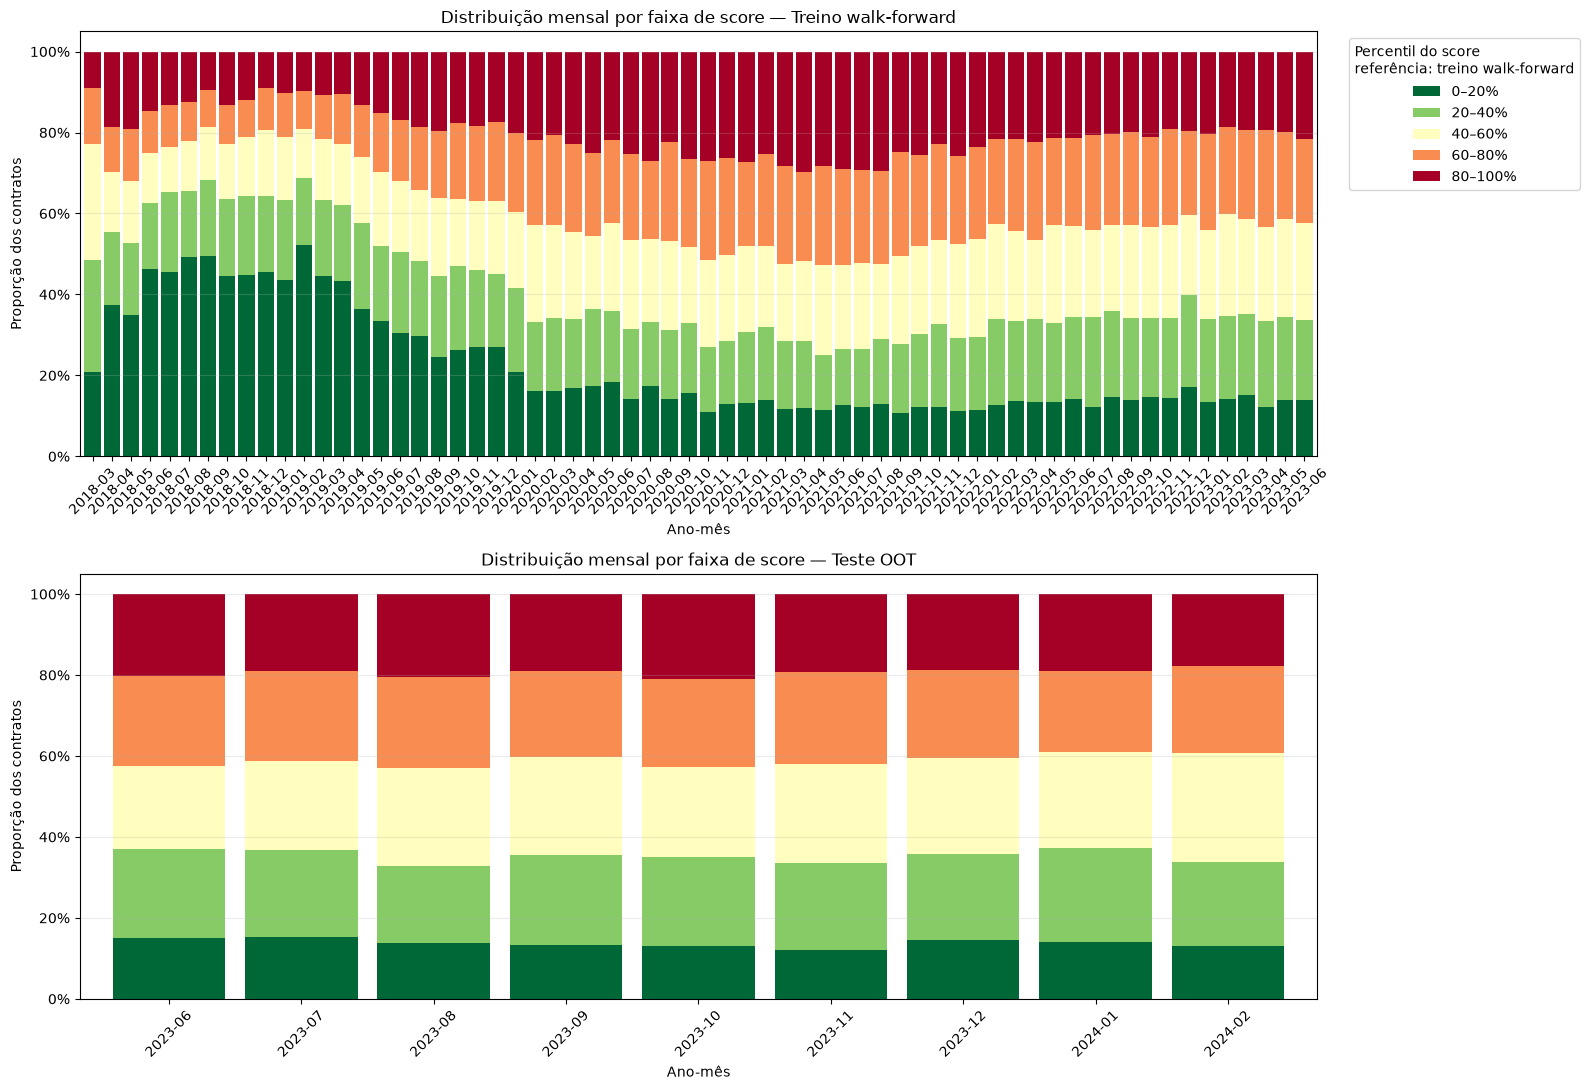

AUC mensal walk-forward no treino:


,mes,n_treino,n_validacao,maus_validacao,auc
0,2018-03,352,779,50,0.5424
1,2018-04,871,839,57,0.5387
2,2018-05,1403,1009,70,0.4952
3,2018-06,2012,994,85,0.5526
4,2018-07,2637,925,76,0.4775
...,...,...,...,...,...
59,2023-02,50456,2128,122,0.6857
60,2023-03,51558,2316,164,0.6533
61,2023-04,53119,2191,133,0.7103
62,2023-05,54575,2321,146,0.6406



Treino walk-forward: taxa observada de maus por mês e faixa


faixa_score,0–20%,20–40%,40–60%,60–80%,80–100%
mes,,,,,
2018-03,0.0307,0.0651,0.0893,0.0748,0.0429
2018-04,0.0575,0.0658,0.0880,0.0753,0.0705
2018-05,0.0652,0.0894,0.0774,0.0465,0.0674
2018-06,0.0697,0.1049,0.0887,0.0583,0.1301
2018-07,0.0853,0.1105,0.0673,0.0625,0.0574
...,...,...,...,...,...
2023-02,0.0165,0.0366,0.0320,0.0779,0.1218
2023-03,0.0287,0.0367,0.0696,0.0706,0.1406
2023-04,0.0302,0.0149,0.0472,0.0653,0.1405


Treino walk-forward: quantidade de contratos por mês e faixa


faixa_score,0–20%,20–40%,40–60%,60–80%,80–100%
mes,,,,,
2018-03,163,215,224,107,70
2018-04,313,152,125,93,156
2018-05,353,179,155,129,193
2018-06,459,162,124,103,146
2018-07,422,181,104,96,122
...,...,...,...,...,...
2023-02,303,437,532,462,394
2023-03,349,463,546,510,448
2023-04,265,470,508,521,427



Teste OOT: taxa observada de maus por mês e faixa


faixa_score,0–20%,20–40%,40–60%,60–80%,80–100%
mes,,,,,
2023-06,0.0297,0.0481,0.0769,0.0852,0.1405
2023-07,0.0210,0.0422,0.0656,0.0941,0.1223
2023-08,0.0361,0.0391,0.0584,0.0899,0.1379
2023-09,0.0336,0.0513,0.0700,0.0880,0.1333
2023-10,0.0338,0.0423,0.0559,0.0874,0.1379
2023-11,0.0346,0.0446,0.0695,0.1158,0.1638
2023-12,0.0458,0.0387,0.0714,0.1185,0.1634
2024-01,0.0119,0.0255,0.0795,0.0989,0.1600
2024-02,0.0200,0.0297,0.0768,0.1061,0.1502


Teste OOT: quantidade de contratos por mês e faixa


faixa_score,0–20%,20–40%,40–60%,60–80%,80–100%
mes,,,,,
2023-06,269,395,364,399,363
2023-07,334,474,488,489,417
2023-08,332,460,582,545,493
2023-09,327,546,600,523,465
2023-10,325,544,555,538,522
2023-11,289,516,590,544,464
2023-12,349,517,574,523,453
2024-01,336,548,566,475,450
2024-02,300,471,612,490,406


In [46]:
# ============================================================
# 1. Configurações
# ============================================================

COL_DATA = "data_decisao"
COL_CLIENTE = "id_cliente"
GAP_DIAS = 360
N_FAIXAS_SCORE = 5

PARAMS_LGBM = {
    "objective": "binary",
    "n_estimators": 500,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 100,
    "colsample_bytree": 0.90,
    "subsample": 0.90,
    "subsample_freq": 1,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}


# ============================================================
# 2. Validações e preparação das datas
# ============================================================

for nome_base, base in [
    ("base_treino", base_treino),
    ("base_teste_oot", base_teste_oot),
]:
    colunas_obrigatorias = [COL_DATA, COL_CLIENTE, COL_TARGET]
    colunas_ausentes = [
        coluna
        for coluna in colunas_obrigatorias
        if coluna not in base.columns
    ]

    if colunas_ausentes:
        raise KeyError(
            f"Colunas ausentes em {nome_base}: {colunas_ausentes}"
        )

    if base[COL_DATA].isna().any():
        raise ValueError(f"Há datas nulas em {nome_base}.")

dados_treino_walk = base_treino.copy()
dados_oot = base_teste_oot.copy()

dados_treino_walk[COL_DATA] = pd.to_datetime(
    dados_treino_walk[COL_DATA],
    errors="coerce",
)
dados_oot[COL_DATA] = pd.to_datetime(
    dados_oot[COL_DATA],
    errors="coerce",
)

if dados_treino_walk[COL_DATA].isna().any():
    raise ValueError("Há datas inválidas após conversão no treino.")

if dados_oot[COL_DATA].isna().any():
    raise ValueError("Há datas inválidas após conversão no OOT.")

dados_treino_walk["_mes_periodo"] = (
    dados_treino_walk[COL_DATA].dt.to_period("M")
)


# ============================================================
# 3. Walk-forward mensal no treino
# ============================================================

registros_scores_treino = []
registros_metricas_mensais = []

meses_treino = sorted(
    dados_treino_walk["_mes_periodo"].dropna().unique()
)

for mes in meses_treino:
    inicio_mes = mes.start_time
    fim_mes = mes.end_time

    validacao = dados_treino_walk.loc[
        dados_treino_walk[COL_DATA].between(
            inicio_mes,
            fim_mes,
            inclusive="both",
        )
    ].copy()

    limite_historico = inicio_mes - pd.Timedelta(days=GAP_DIAS)

    treino_fold = dados_treino_walk.loc[
        dados_treino_walk[COL_DATA] < limite_historico
    ].copy()

    # Evita que clientes do mês avaliado apareçam no treino desse fold.
    clientes_validacao = validacao[COL_CLIENTE].dropna().unique()
    treino_fold = treino_fold.loc[
        ~treino_fold[COL_CLIENTE].isin(clientes_validacao)
    ].copy()

    if treino_fold.empty or validacao.empty:
        continue

    if treino_fold[COL_TARGET].nunique() < 2:
        continue

    # Seleciona e prepara as features usando o helper do projeto.
    X_fold_treino = fn.preparar_X(
        treino_fold,
        FEATURES_MODELO,
    )
    X_fold_validacao = fn.preparar_X(
        validacao,
        FEATURES_MODELO,
    )

    # Define as categorias exclusivamente a partir do treino do fold.
    # Valores de categoria inéditos no mês de validação tornam-se ausentes.
    for coluna in FEATURES_CATEGORICAS:
        categorias_fold = (
            X_fold_treino[coluna]
            .astype("string")
            .dropna()
            .unique()
            .tolist()
        )

        dtype_categoria = pd.CategoricalDtype(
            categories=sorted(categorias_fold),
            ordered=False,
        )

        X_fold_treino[coluna] = (
            X_fold_treino[coluna]
            .astype("string")
            .astype(dtype_categoria)
        )
        X_fold_validacao[coluna] = (
            X_fold_validacao[coluna]
            .astype("string")
            .astype(dtype_categoria)
        )

    modelo_fold = LGBMClassifier(**PARAMS_LGBM)

    modelo_fold.fit(
        X_fold_treino,
        treino_fold[COL_TARGET].astype("int8"),
        categorical_feature=FEATURES_CATEGORICAS,
    )

    score_validacao = modelo_fold.predict_proba(
        X_fold_validacao
    )[:, 1]

    y_validacao = validacao[COL_TARGET].astype("int8").to_numpy()
    auc_mes, _ = fn.metricas(y_validacao, score_validacao)

    registros_scores_treino.append(
        pd.DataFrame({
            "indice_base": validacao.index.to_numpy(),
            "data_decisao": validacao[COL_DATA].to_numpy(),
            "mes": str(mes),
            "target": y_validacao,
            "score_modelo": score_validacao,
        })
    )

    registros_metricas_mensais.append({
        "mes": str(mes),
        "inicio_validacao": inicio_mes.date(),
        "fim_validacao": fim_mes.date(),
        "n_treino": len(treino_fold),
        "maus_treino": int(treino_fold[COL_TARGET].sum()),
        "n_validacao": len(validacao),
        "maus_validacao": int(validacao[COL_TARGET].sum()),
        "auc": auc_mes,
    })

if not registros_scores_treino:
    raise ValueError(
        "Nenhum mês gerou previsões walk-forward. "
        "Verifique as datas, o tamanho do histórico e o gap."
    )

scores_treino_walk = pd.concat(
    registros_scores_treino,
    ignore_index=True,
)

metricas_walk_forward = pd.DataFrame(
    registros_metricas_mensais
)


# ============================================================
# 4. Modelo treinado no treino completo e aplicado ao OOT
# ============================================================

X_treino_completo = fn.preparar_X(
    base_treino,
    FEATURES_MODELO,
)
X_oot = fn.preparar_X(
    base_teste_oot,
    FEATURES_MODELO,
)

# O modelo final aprende categorias usando todo o treino.
# Categorias inéditas no OOT são convertidas em ausentes.
for coluna in FEATURES_CATEGORICAS:
    categorias_treino_completo = (
        X_treino_completo[coluna]
        .astype("string")
        .dropna()
        .unique()
        .tolist()
    )

    dtype_categoria = pd.CategoricalDtype(
        categories=sorted(categorias_treino_completo),
        ordered=False,
    )

    X_treino_completo[coluna] = (
        X_treino_completo[coluna]
        .astype("string")
        .astype(dtype_categoria)
    )
    X_oot[coluna] = (
        X_oot[coluna]
        .astype("string")
        .astype(dtype_categoria)
    )

modelo_lgbm_treino_completo = LGBMClassifier(**PARAMS_LGBM)

modelo_lgbm_treino_completo.fit(
    X_treino_completo,
    base_treino[COL_TARGET].astype("int8"),
    categorical_feature=FEATURES_CATEGORICAS,
)

score_oot_treino_completo = modelo_lgbm_treino_completo.predict_proba(
    X_oot
)[:, 1]

scores_oot_walk = pd.DataFrame({
    "data_decisao": dados_oot[COL_DATA].to_numpy(),
    "mes": (
        dados_oot[COL_DATA]
        .dt.to_period("M")
        .astype("string")
        .to_numpy()
    ),
    "target": y_teste_oot.to_numpy(),
    "score_modelo": score_oot_treino_completo,
})


# ============================================================
# 5. Transformação em percentis e criação das cinco faixas
# ============================================================

# A referência do transformer são os scores walk-forward do treino.
# Isso permite comparar treino e OOT na mesma escala relativa.
quantile_transformer = QuantileTransformer(
    n_quantiles=min(1000, len(scores_treino_walk)),
    output_distribution="uniform",
    random_state=SEED,
)

scores_treino_walk["quantil_score"] = (
    quantile_transformer
    .fit_transform(scores_treino_walk[["score_modelo"]])
    .ravel()
)

scores_oot_walk["quantil_score"] = (
    quantile_transformer
    .transform(scores_oot_walk[["score_modelo"]])
    .ravel()
)

limites_faixas = np.linspace(
    0.0,
    1.0,
    N_FAIXAS_SCORE + 1,
)

rotulos_faixas = [
    f"{inicio:.0f}–{fim:.0f}%"
    for inicio, fim in zip(
        limites_faixas[:-1] * 100,
        limites_faixas[1:] * 100,
    )
]

for scores in [scores_treino_walk, scores_oot_walk]:
    scores["faixa_score"] = pd.cut(
        scores["quantil_score"].clip(0.0, 1.0),
        bins=limites_faixas,
        labels=rotulos_faixas,
        include_lowest=True,
        right=True,
    )

scores_treino_walk["particao"] = "Treino walk-forward"
scores_oot_walk["particao"] = "Teste OOT"

scores_mensais = pd.concat(
    [scores_treino_walk, scores_oot_walk],
    ignore_index=True,
)


# ============================================================
# 6. Distribuição mensal por faixa e métricas observadas
# ============================================================

distribuicao_mensal = (
    scores_mensais
    .groupby(
        ["particao", "mes", "faixa_score"],
        observed=False,
    )
    .size()
    .rename("quantidade")
    .reset_index()
)

totais_mensais = (
    scores_mensais
    .groupby(
        ["particao", "mes"],
        observed=False,
    )
    .size()
    .rename("total_mes")
    .reset_index()
)

distribuicao_mensal = distribuicao_mensal.merge(
    totais_mensais,
    on=["particao", "mes"],
    how="left",
    validate="many_to_one",
)

distribuicao_mensal["percentual_mes"] = (
    distribuicao_mensal["quantidade"]
    / distribuicao_mensal["total_mes"]
)

# A taxa de maus é observada retrospectivamente, não é uma probabilidade
# calibrada. A contagem deve ser considerada ao interpretar cada taxa.
resumo_mensal_faixa = (
    scores_mensais
    .groupby(
        ["particao", "mes", "faixa_score"],
        observed=False,
    )
    .agg(
        quantidade=("target", "size"),
        taxa_observada_maus=("target", "mean"),
        score_medio=("score_modelo", "mean"),
    )
    .reset_index()
)


# ============================================================
# 7. Gráfico mensal
# ============================================================

particoes_grafico = [
    "Treino walk-forward",
    "Teste OOT",
]

fig, eixos = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 11),
    sharey=True,
)

for eixo, particao in zip(eixos, particoes_grafico):
    dados_particao = distribuicao_mensal.loc[
        distribuicao_mensal["particao"].eq(particao)
    ]

    tabela_plot = (
        dados_particao
        .pivot(
            index="mes",
            columns="faixa_score",
            values="percentual_mes",
        )
        .reindex(columns=rotulos_faixas)
        .sort_index()
    )

    tabela_plot.plot(
        kind="bar",
        stacked=True,
        ax=eixo,
        colormap="RdYlGn_r",
        width=0.85,
        legend=False,
    )

    eixo.set_title(
        f"Distribuição mensal por faixa de score — {particao}"
    )
    eixo.set_xlabel("Ano-mês")
    eixo.set_ylabel("Proporção dos contratos")
    eixo.yaxis.set_major_formatter(
        PercentFormatter(xmax=1.0)
    )
    eixo.tick_params(axis="x", rotation=45)
    eixo.grid(axis="y", alpha=0.25)

eixos[0].legend(
    title="Percentil do score\nreferência: treino walk-forward",
    labels=rotulos_faixas,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. Tabelas de acompanhamento
# ============================================================

print("AUC mensal walk-forward no treino:")
display(
    metricas_walk_forward[
        [
            "mes",
            "n_treino",
            "n_validacao",
            "maus_validacao",
            "auc",
        ]
    ].round({"auc": 4})
)

for particao in particoes_grafico:
    resumo_particao = resumo_mensal_faixa.loc[
        resumo_mensal_faixa["particao"].eq(particao)
    ]

    print(
        f"\n{particao}: taxa observada de maus por mês e faixa"
    )

    tabela_taxas = (
        resumo_particao
        .pivot(
            index="mes",
            columns="faixa_score",
            values="taxa_observada_maus",
        )
        .reindex(columns=rotulos_faixas)
        .sort_index()
        .round(4)
    )
    display(tabela_taxas)

    print(f"{particao}: quantidade de contratos por mês e faixa")

    tabela_quantidades = (
        resumo_particao
        .pivot(
            index="mes",
            columns="faixa_score",
            values="quantidade",
        )
        .reindex(columns=rotulos_faixas)
        .sort_index()
    )
    display(tabela_quantidades)

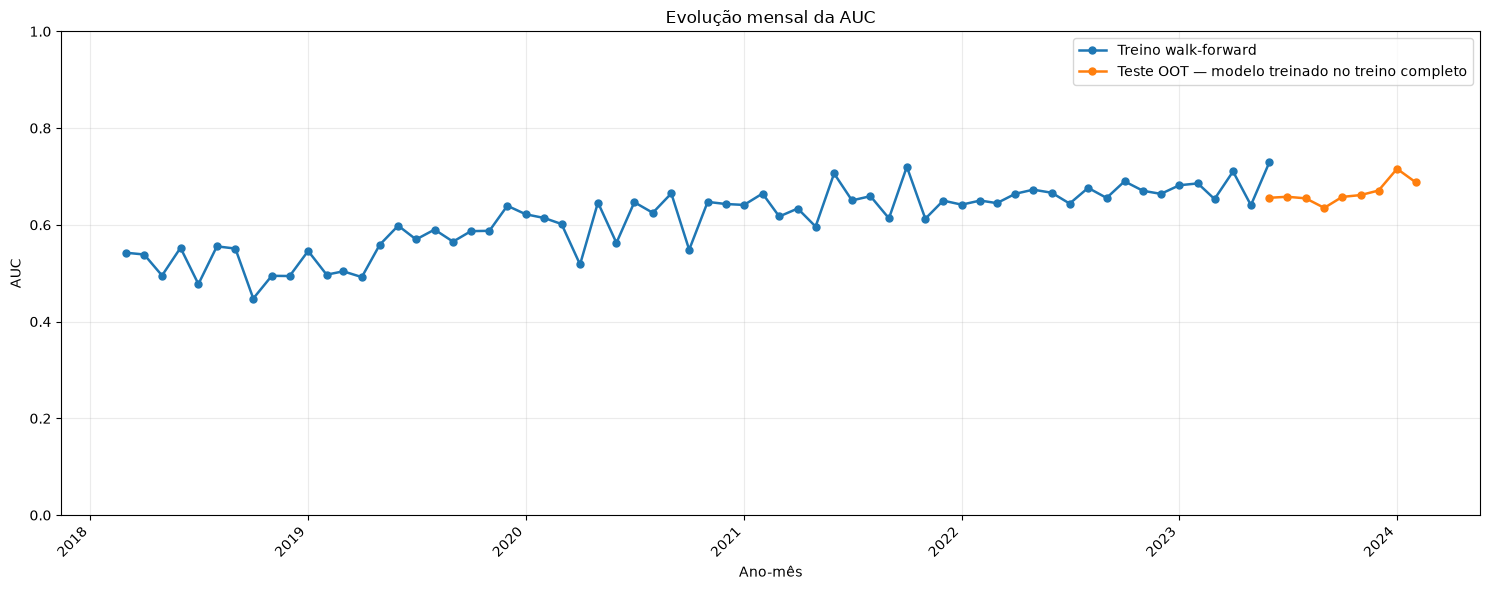

AUC e quantidade de observações por mês:


,particao,mes,n,maus,bons,auc
0,Teste OOT,2023-06,1790,140,1650,0.6559
1,Teste OOT,2023-07,2202,156,2046,0.6580
2,Teste OOT,2023-08,2412,181,2231,0.6548
3,Teste OOT,2023-09,2461,189,2272,0.6351
4,Teste OOT,2023-10,2484,184,2300,0.6577
...,...,...,...,...,...,...
68,Treino walk-forward,2023-02,2128,122,2006,0.6857
69,Treino walk-forward,2023-03,2316,164,2152,0.6533
70,Treino walk-forward,2023-04,2191,133,2058,0.7103
71,Treino walk-forward,2023-05,2321,146,2175,0.6406


In [47]:
# ============================================================
# AUC mensal: treino walk-forward e teste OOT
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def calcular_auc_mensal(df_scores, nome_particao):
    """Calcula AUC e contagens por mês; AUC fica NaN se houver uma só classe."""
    registros = []

    for mes, grupo in df_scores.groupby("mes", sort=True, observed=True):
        y_mes = grupo["target"].astype("int8").to_numpy()
        score_mes = grupo["score_modelo"].to_numpy()

        auc_mes, _ = fn.metricas(y_mes, score_mes)

        registros.append({
            "particao": nome_particao,
            "mes": str(mes),
            "n": len(grupo),
            "maus": int(y_mes.sum()),
            "bons": int(len(y_mes) - y_mes.sum()),
            "auc": auc_mes,
        })

    return pd.DataFrame(registros)


# Confere se as colunas esperadas existem nas tabelas de scores.
colunas_scores = {"mes", "target", "score_modelo"}

for nome, df_scores in [
    ("scores_treino_walk", scores_treino_walk),
    ("scores_oot_walk", scores_oot_walk),
]:
    colunas_ausentes = colunas_scores.difference(df_scores.columns)

    if colunas_ausentes:
        raise KeyError(
            f"Colunas ausentes em {nome}: {sorted(colunas_ausentes)}"
        )


auc_mensal_treino = calcular_auc_mensal(
    scores_treino_walk,
    "Treino walk-forward",
)

auc_mensal_oot = calcular_auc_mensal(
    scores_oot_walk,
    "Teste OOT",
)

auc_mensal = pd.concat(
    [auc_mensal_treino, auc_mensal_oot],
    ignore_index=True,
)

# Converte o rótulo AAAA-MM em data para garantir ordenação cronológica.
auc_mensal["mes_data"] = pd.to_datetime(
    auc_mensal["mes"] + "-01",
    format="%Y-%m-%d",
    errors="coerce",
)

auc_mensal = auc_mensal.sort_values(
    ["particao", "mes_data"]
).reset_index(drop=True)


# ============================================================
# Gráfico de AUC mês a mês
# ============================================================

fig, ax = plt.subplots(figsize=(15, 6))

configuracoes_grafico = [
    (
        auc_mensal_treino,
        "Treino walk-forward",
        "tab:blue",
    ),
    (
        auc_mensal_oot,
        "Teste OOT — modelo treinado no treino completo",
        "tab:orange",
    ),
]

for dados, rotulo, cor in configuracoes_grafico:
    dados_plot = dados.copy()
    dados_plot["mes_data"] = pd.to_datetime(
        dados_plot["mes"] + "-01",
        format="%Y-%m-%d",
        errors="coerce",
    )

    dados_plot = dados_plot.dropna(subset=["auc", "mes_data"])

    ax.plot(
        dados_plot["mes_data"],
        dados_plot["auc"],
        marker="o",
        linewidth=1.8,
        markersize=5,
        color=cor,
        label=rotulo,
    )

ax.set_title("Evolução mensal da AUC")
ax.set_xlabel("Ano-mês")
ax.set_ylabel("AUC")
ax.set_ylim(0.0, 1.0)
ax.grid(axis="both", alpha=0.25)
ax.legend()

fig.autofmt_xdate(rotation=45)
plt.tight_layout()
plt.show()


# Tabela de apoio para interpretar a AUC mensal.
print("AUC e quantidade de observações por mês:")
display(
    auc_mensal[
        ["particao", "mes", "n", "maus", "bons", "auc"]
    ].round({"auc": 4})
)